In [1]:
import numpy as np
import glob
import matplotlib.pyplot as plt
import os
import re
import pandas as pnd
#from os import listdir
#from os.path import isfile, join
plt.style.use('seaborn')

In [2]:
print("Working dir: ", os.getcwd())

# Set variables
PROBLEM_PATH = "../problems/pure_int_bench"
LP = "LP"
CUT = "Cut"

Working dir:  /home/dimitry_42/source/ilpcuts/scripts


In [29]:
# Get problem names
problem_set = [f for f in listdir(PROBLEM_PATH)
                 if isfile(join(PROBLEM_PATH, f)) and ":Zone.Identifier" not in f]

In [3]:
# Get folder with results
# input_folder = input()
input_folder = "../build/CPlexCutsPower_22.08.2022_Mon_09-02"
print(input_folder + "/*_result.txt")

../build/CPlexCutsPower_22.08.2022_Mon_09-02/*_result.txt


In [14]:
def parse_file(file_path):
    res = []
    with open(file_path, mode="r") as file:
        for line in file:
            if not line.strip(): 
                continue
            cut_type = re.search(r"(?<=Cut-type = \")[^\"]+(?=\":)", line)[0]
            LP_diff_str = re.search(r"(?<=\bLP Diff\. = )-?\d+[.,]?\d*([eE][-+]\d+)?(?=;)",line)[0]
            LP_diff = float(LP_diff_str)
            res.append((cut_type, LP_diff))
    return res

res = parse_file(input_folder+"/sorrell3.mps.gz_results.txt")
#print(res)

In [25]:
def create_data_frame(parse_info):
    df = pnd.DataFrame(parse_info, columns =['Cut-Name', 'Abs-Diff'])
    df['Abs-Diff'] = df['Abs-Diff'].abs()
    cplex_cuts_df = df[~df['Cut-Name'].isin(["my","my+all"])]
    max_idx = cplex_cuts_df['Abs-Diff'].idxmax()
    MaxAbsDiff = cplex_cuts_df['Abs-Diff'][max_idx]
    df['Perc-Diff'] = df['Abs-Diff'] / MaxAbsDiff

    return df

df = create_data_frame(res)
df

,Cut-Name,Abs-Diff,Perc-Diff
0,all,492.050,1.000000
1,clique,492.036,0.999972
2,cover,490.562,0.996976
3,disj,490.562,0.996976
4,flowc,490.562,0.996976
5,flowp,490.562,0.996976
6,gomory,490.562,0.996976
7,gub,490.562,0.996976
8,impliedg,490.562,0.996976
9,impliedl,490.562,0.996976


In [45]:
for file_path in glob.glob(input_folder + "/*_results.txt"):
    match = re.search(r"(?<=/)[^/]+(?=_result)", file_path)
    prob_name = match[0]
    parse_res = parse_file(file_path)
    

supportcase30.mps.gz
seymour.mps.gz
glass-sc.mps.gz
pb-market-split8-70-4.mps.gz
neos859080.mps.gz
cod105_vc1024.mps.gz
sorrell7.mps.gz
graph20-20-1rand.mps.gz
sorrell4.mps.gz
sorrell3.mps.gz
ramos3.mps.gz
reblock115.mps.gz
circ10-3.mps.gz
enlight_hard.mps.gz
neos-3381206-awhea.mps.gz
supportcase2.mps.gz


In [32]:
# parser function
def parser(file_path : str) -> dict:
    result = {}
    result[LP] = {}
    with open(file_path) as my_file:
        for line in my_file:
            # clear line
            line = line.strip()
            # get position
            first_quote = line.find('"')
            second_quote = line.find('"', first_quote + 1)
            second_equal = line.find("=", line.find("=") + 1)
            last_equal = line.rfind("=")
            semicolon = line.find(";")
            # get values
            cut_type = line[first_quote + 1 : second_quote]
            lp_diff = abs(float(line[second_equal + 2 : semicolon]))
            cutoff_diff = abs(float(line[last_equal + 2 : ]))
            # fill the dictionary with new values
            result[LP][cut_type] = lp_diff
    return result


In [79]:
def set_dict() -> table:
    table = {}
    table["Absolute"] = {}
    table["LP"]["Percent"] = {}
    for row in ["Absolute", "Percent"]:
        for data_arr in ["x", "y", "colors"]:
            table[row][data_arr] = []
            table[row]["to_graph"] = True
            table[row]["max_type"] = None
    return table

In [81]:
def get_positions(data : dict) -> dict:
    positions = {}
    positions["size_x"], positions["size_y"] = 2, 2
    positions["positions"] = []
    lp_abs, lp_per = data["LP"]["Absolute"]["to_graph"], data["LP"]["Percent"]["to_graph"]
    cut_abs, cut_per = data["Cut"]["Absolute"]["to_graph"], data["Cut"]["Percent"]["to_graph"]
    if not lp_abs and not cut_abs:
        return {}
    positions["positions"].append({"metric_type" : "LP", "value_type" : "Absolute",
                                       "coord" : (0, 0), "to_graph" : True if lp_abs else False})
    positions["positions"].append({"metric_type" : "LP", "value_type" : "Percent",
                                       "coord" : (0, 1), "to_graph" : True if lp_abs and lp_per else False})
    positions["positions"].append({"metric_type" : "Cut", "value_type" : "Absolute",
                                       "coord" : (1, 0), "to_graph" : True if cut_abs else False})
    positions["positions"].append({"metric_type" : "Cut", "value_type" : "Percent",
                                       "coord" : (1, 1), "to_graph" : True if cut_abs and cut_per else False})
    return positions

In [77]:
def one_graph(axes, data : dict, position : dict) -> None:
    i, j = position["coord"]
    metric_type = position["metric_type"]
    value_type = position["value_type"]
    title = metric_type + " " + value_type
    d = data[metric_type][value_type]
    if position["to_graph"]:
        try:
            axes[i][j].tick_params(axis="x", labelsize=15, labelrotation=75)
            axes[i][j].tick_params(axis="y", labelsize=15)
            axes[i][j].bar(x=d["X"], height=d["y"], color=d["colors"])
            axes[i][j].set_title(title, fontsize=20)
        except TypeError:
            axes.tick_params(axis="x", labelsize=15, labelrotation=75)
            axes.tick_params(axis="y", labelsize=15)
            axes.bar(x=d["X"], height=d["y"], color=d["colors"])
            axes.set_title(title, fontsize=20)
    else:
        axes[i][j].remove()

In [76]:
def calc_absolute(values : dict, data : dict) -> None:
    data["X"] = list(filter(lambda x : x in ["my", "my+all", "none"] or values[x] != values["none"], values))
    data["y"] = [values[x] for x in data["X"]]
    data["colors"] = ["blue"] * len(data["X"])
    for mode in ["my", "my+all"]:
        if mode in data["X"]:
            data["colors"][data["X"].index(mode)] = "red"
    if len(data["X"]) == 3 and values["none"] == values["my"] and values["none"] == values["my+all"]:
        data["to_graph"] = False
    elif len(data["X"]) > 3:
        tmp_arr = filter(lambda x : x[0] not in ["my", "my+all", "none"], zip(data["X"], data["y"]))
        max_type, _ = max(tmp_arr, key=lambda x : values["none"] - x[1])
        data["colors"][data["X"].index(max_type)] = "green"

In [75]:
def calc_percent(values : dict, data : dict) -> None:
    pairs = [(x, values["none"] - values[x]) for x in values]
    pairs = list(filter(lambda x: x[1] != 0, pairs))
    not_my_pairs = list(filter(lambda x: x[0] not in ["my", "my+all"], pairs))
    if not_my_pairs:
        max_type, max_value = max(not_my_pairs, key=lambda x: x[1])
        pairs = list(map(lambda x: (x[0], abs((max_value - x[1]) / max_value) * 100 + 100) if x[1] > max_value
                             else  (x[0],-abs((max_value - x[1]) / max_value) * 100 + 100), pairs))
        data["y"] = [x[1] for x in pairs]
        data["X"] = [x[0] for x in pairs]
        data["colors"] = ["blue"] * len(data["X"])
        data["colors"][data["X"].index(max_type)] = "green"
        for mode in ["my", "my+all"]:
            if mode in data["X"]:
                data["colors"][data["X"].index(mode)] = "red"
    else:
        data["to_graph"] = False

In [74]:
def main_graph(values : dict, problem : str) -> None:
    data = set_dict()
    for diff in ["LP", "Cut"]:
        calc_absolute(values[diff], data[diff]["Absolute"])
        calc_percent(values[diff], data[diff]["Percent"])
    positions = get_positions(data)
    if positions:
        fig, axes = plt.subplots(positions["size_x"], positions["size_y"], figsize=(35, 25))
        fig.suptitle(problem, fontsize=40)
        for position in positions["positions"]:
            one_graph(axes, data, position)
    else:
        print(problem + ": no results")

enlight_hard: no results


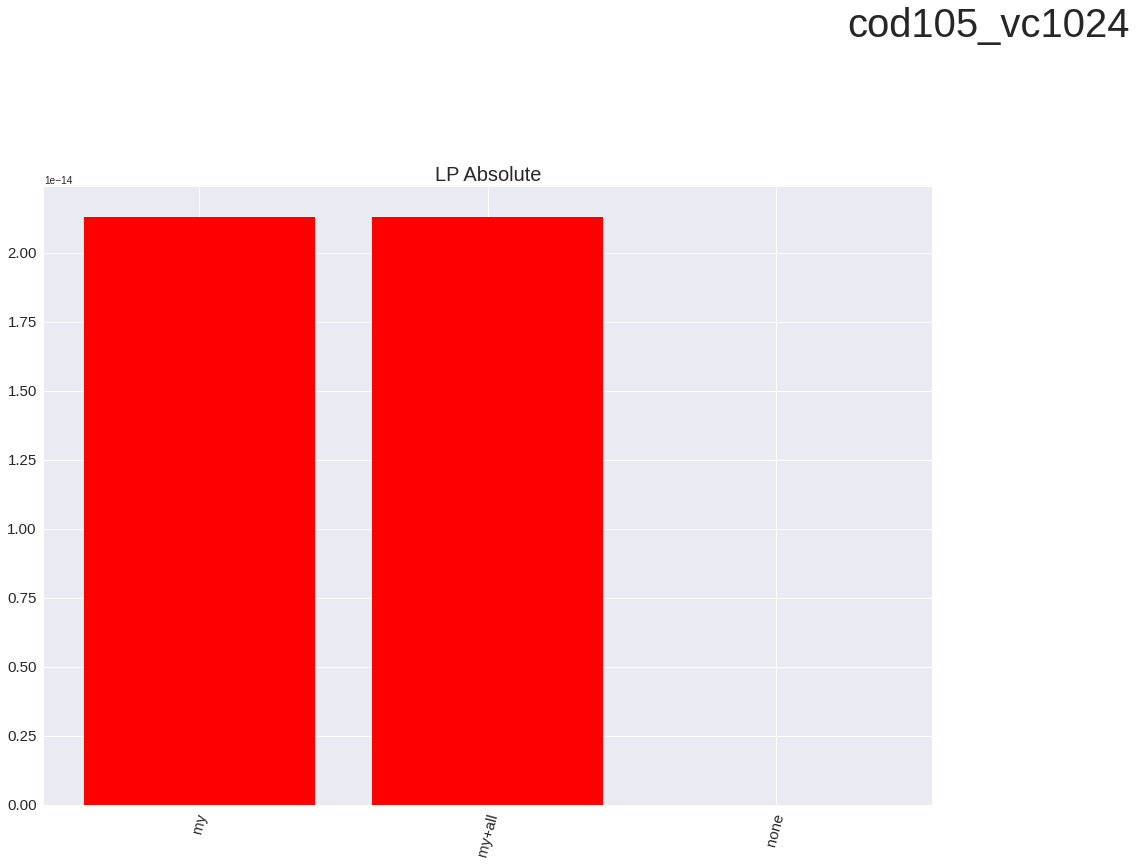

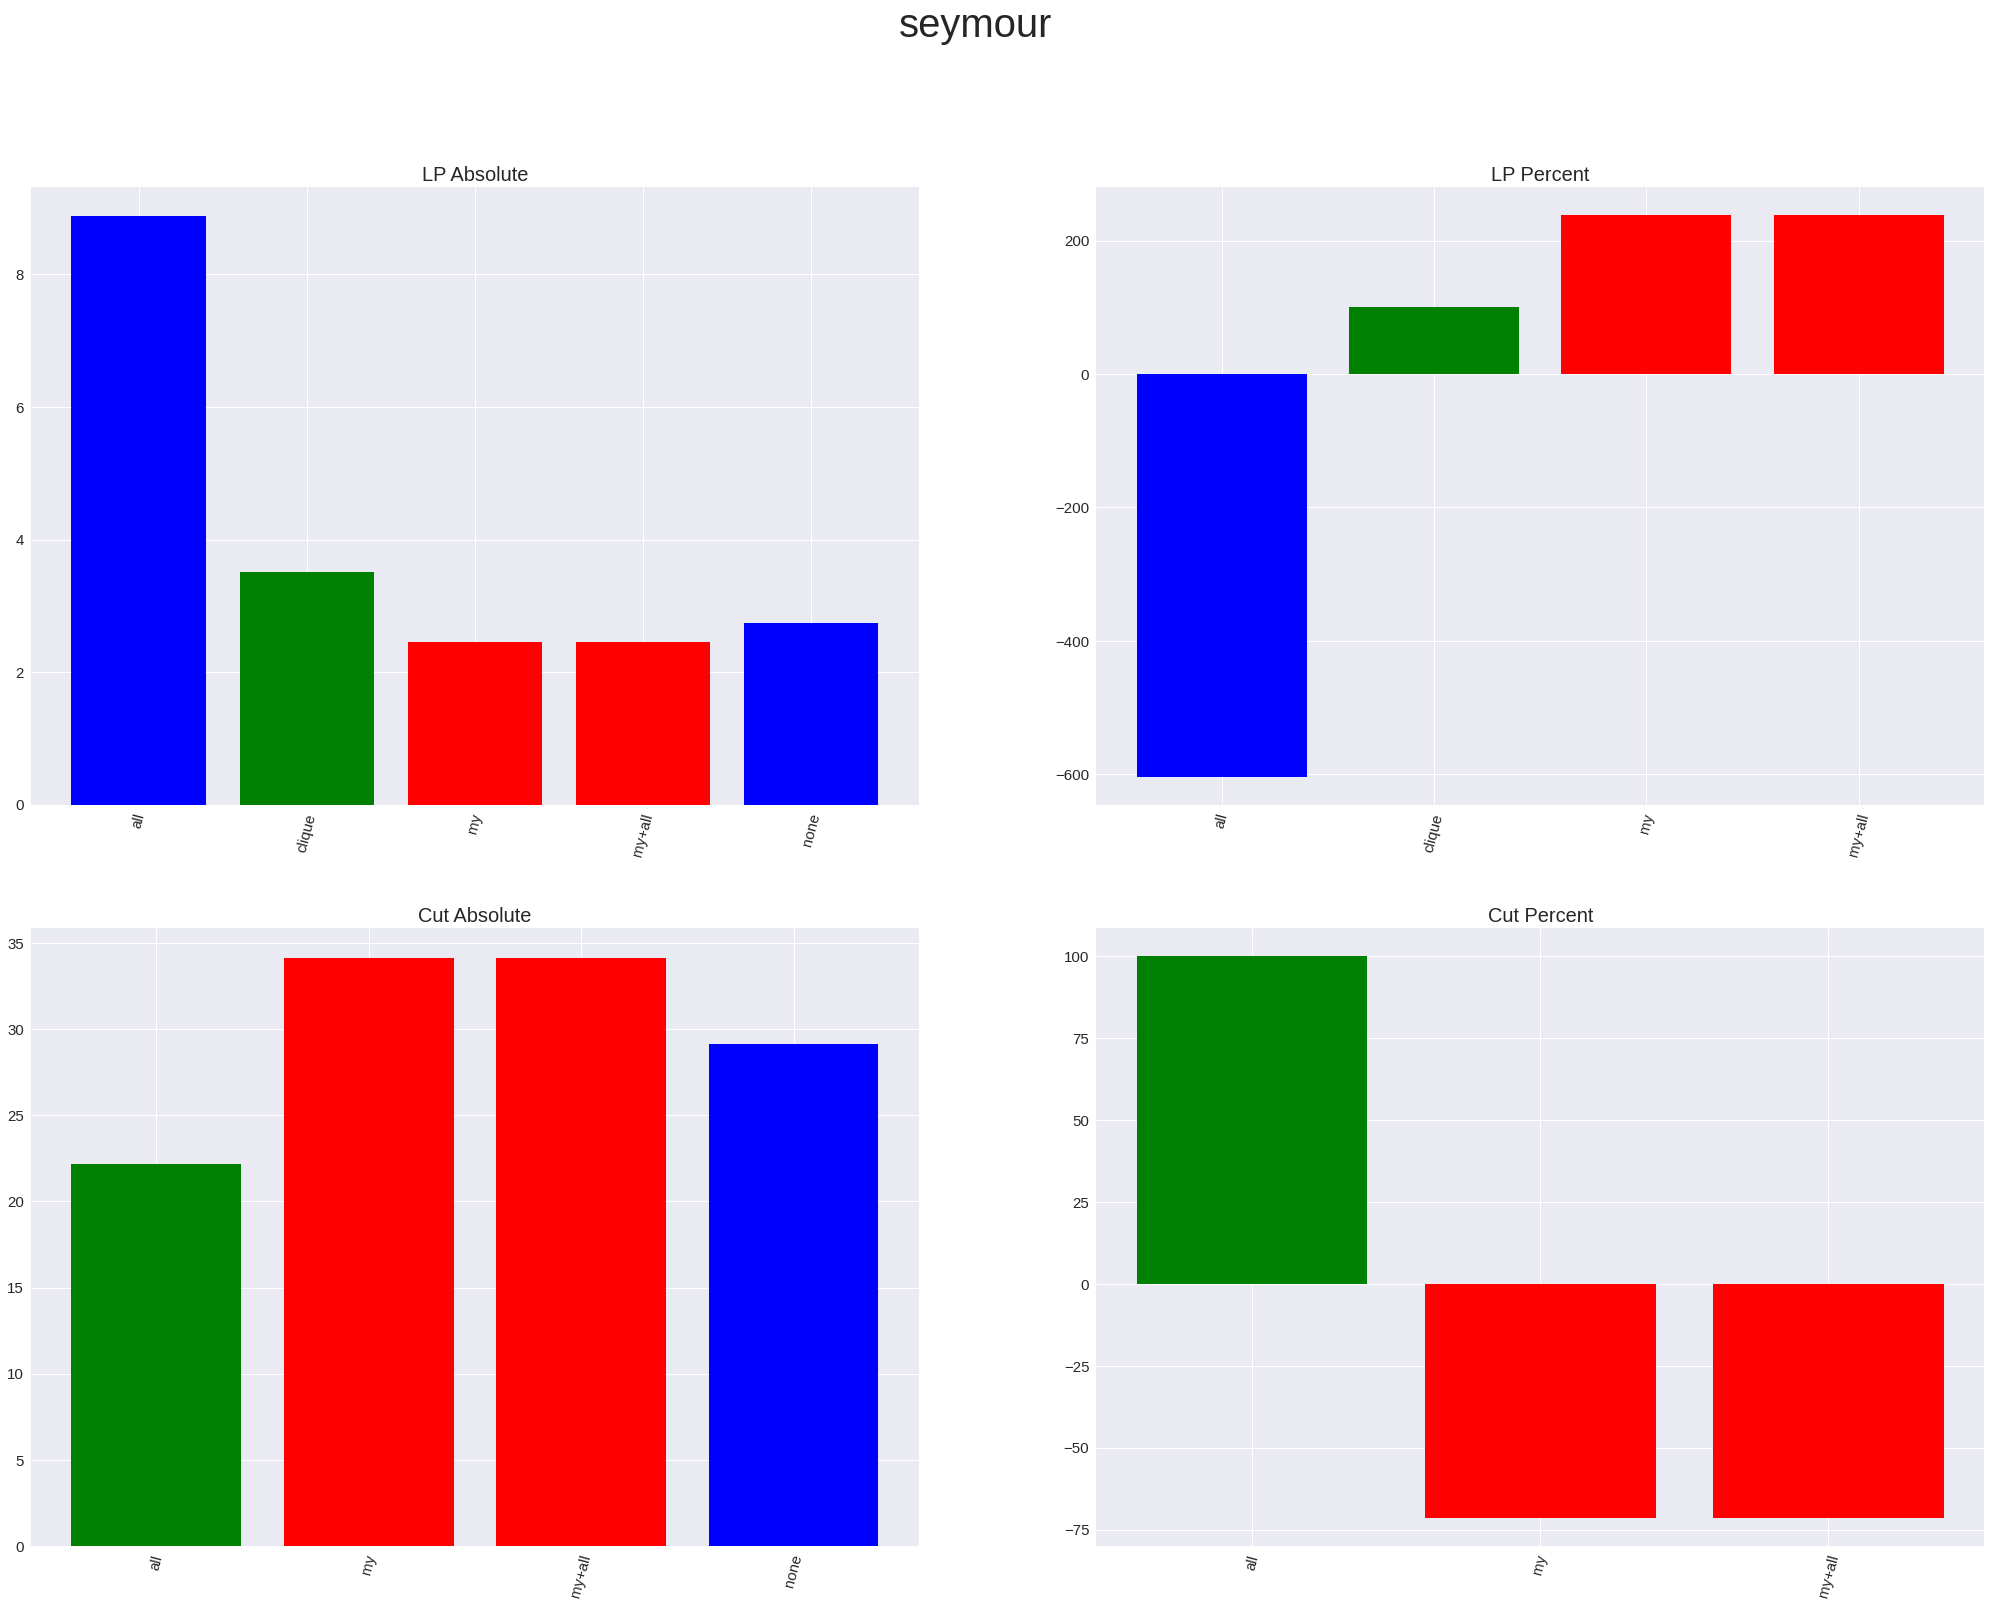

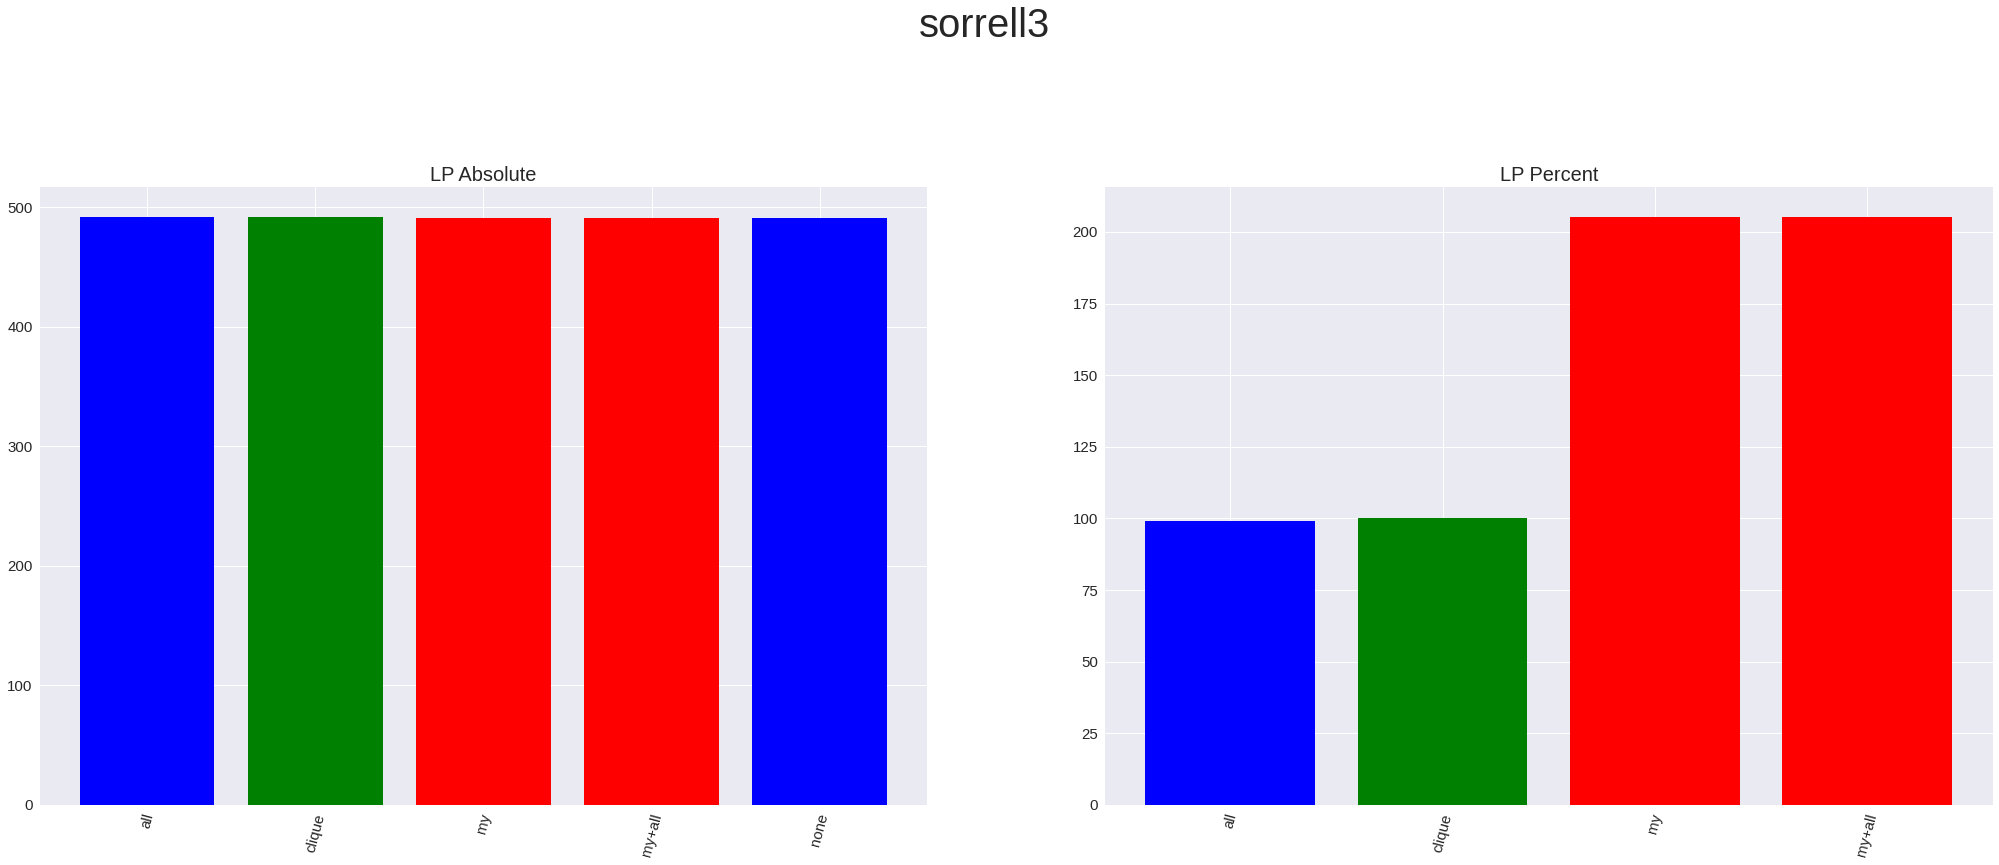

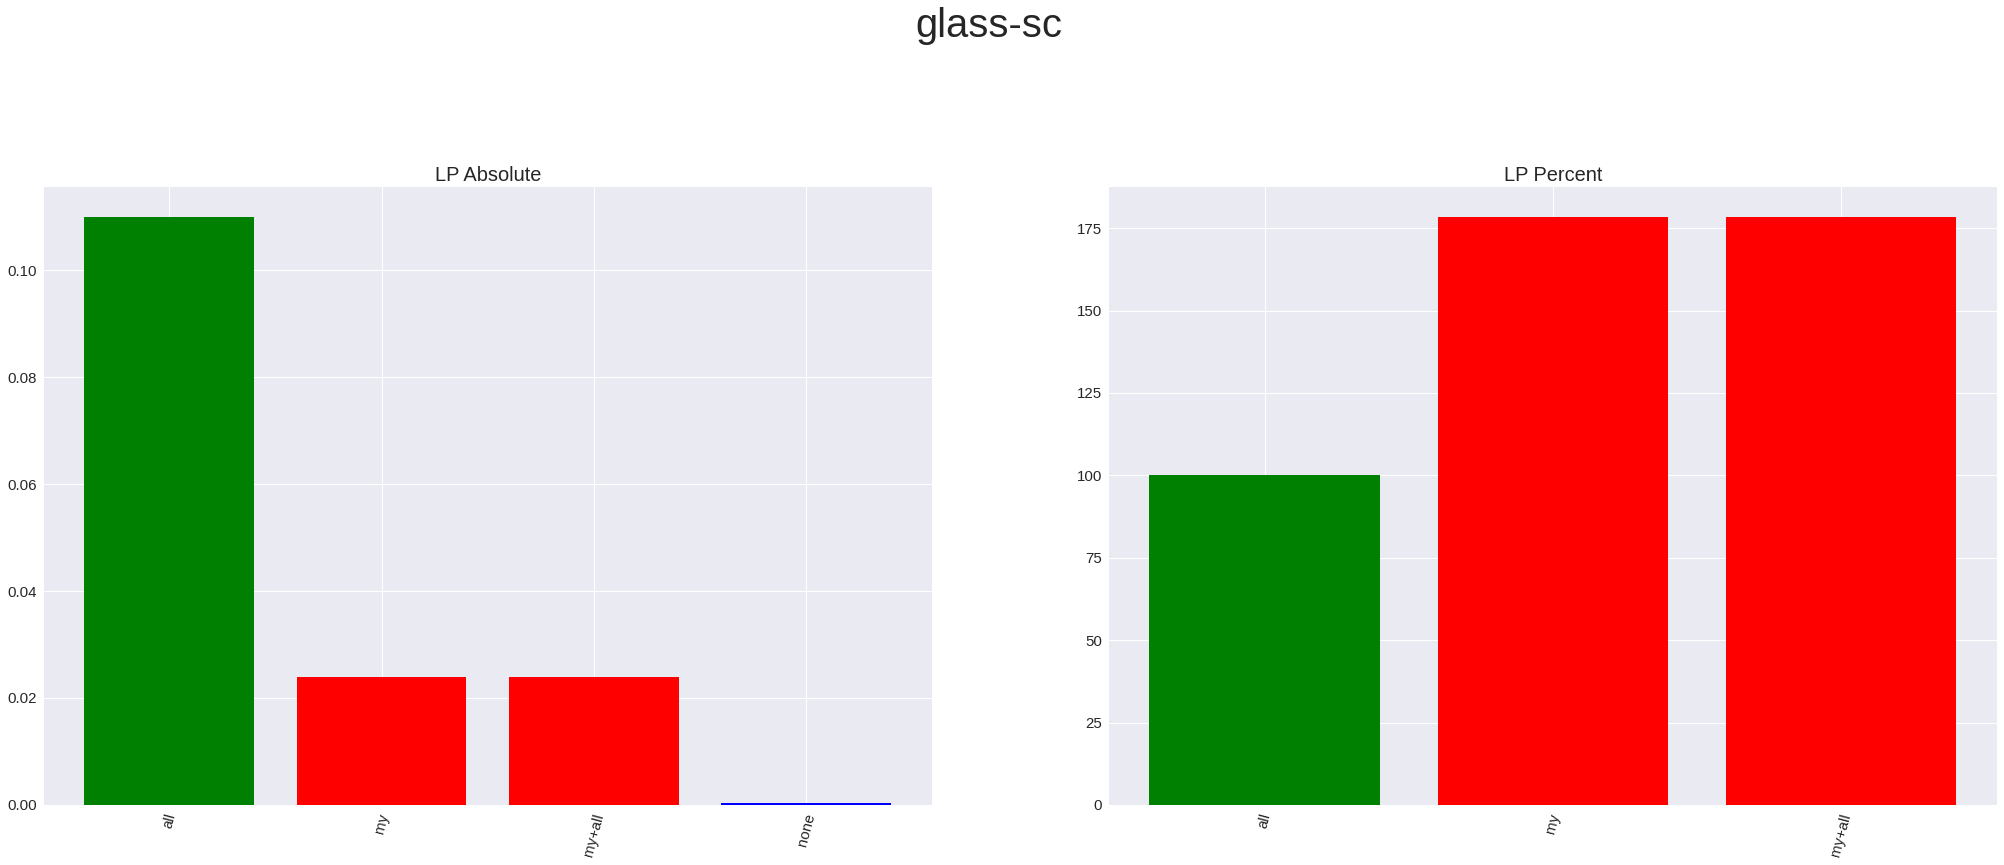

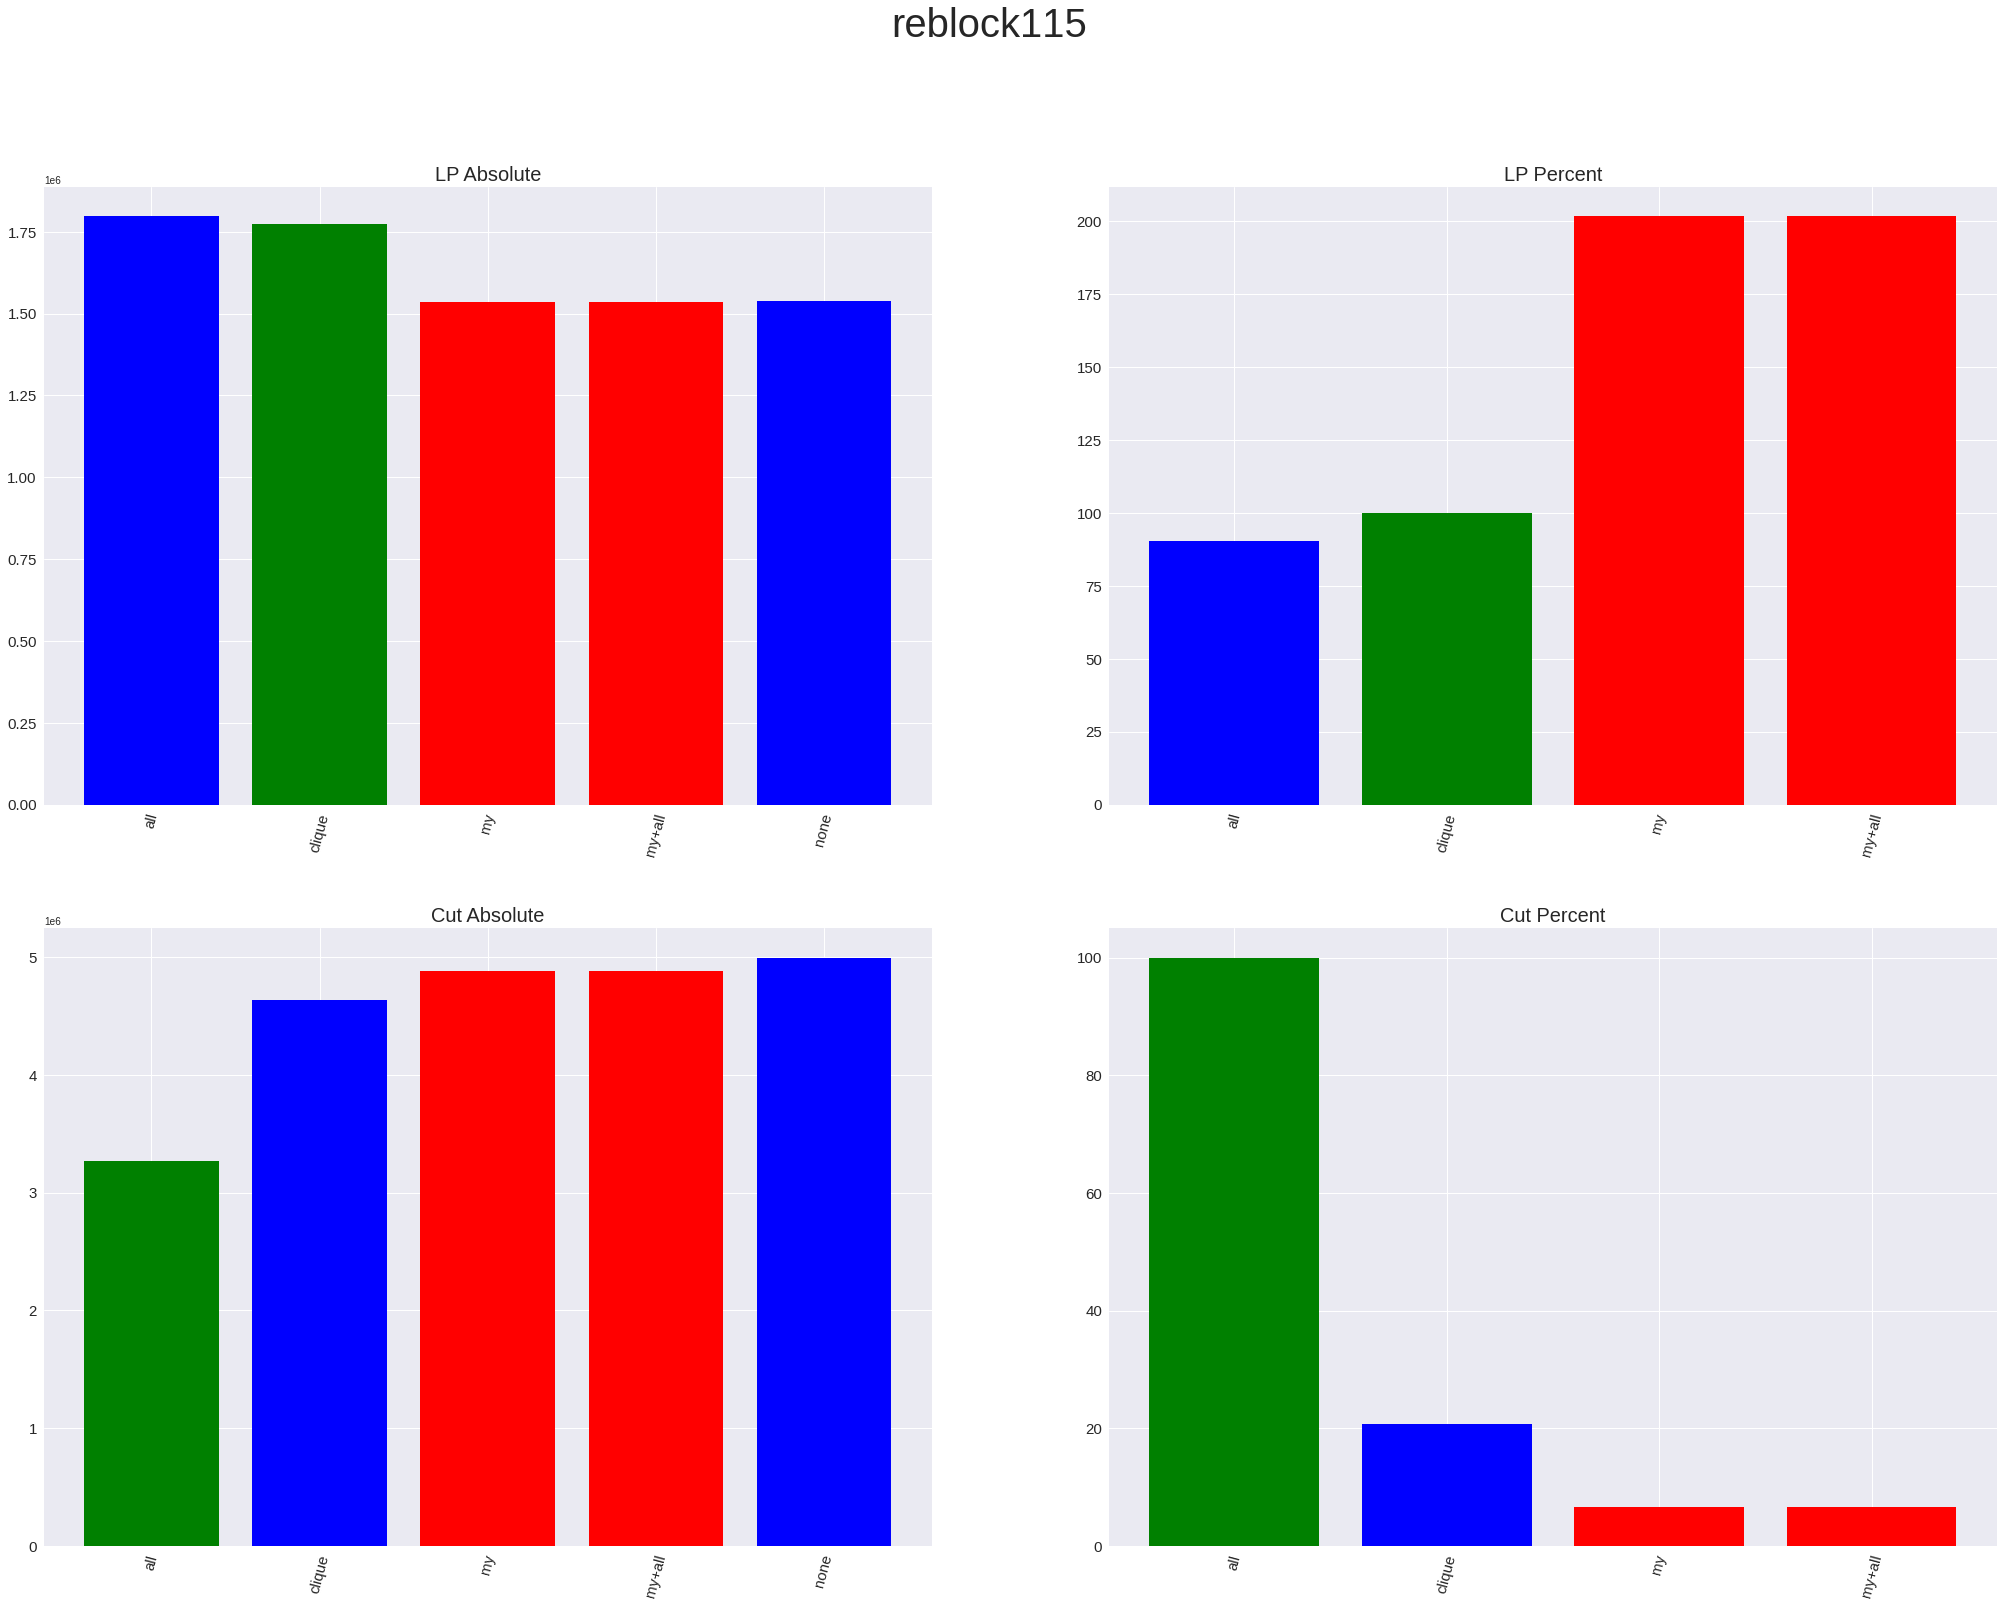

In [82]:
# main program
for p in problem_set:
    problem_path = join(folder, p + "_results.txt")
    if isfile(problem_path):
        values = parser(problem_path)
        if values[LP] and values[CUT]:
            main_graph(values=values, problem=p[ : p.find(".")])